# Dataset Audit

This notebook contains a thorough audit of the chosen dataset, the Brown Corpus,
for the purposes of this project.

Jupyter notebook is the chosen format for this audit, as it's much simpler to see and visualise
both the commands, i.e. what's actually happening, as well as their results and accompanying text descriptions.

Functional pieces of code remain in their respective Python modules (`*.py` files in the current directory),
and are imported here when necessary.

## Running the code

To ensure all code in this Jupyter notebook can run, make sure to use a Kernel associated with a virtual environment
set up for the `dataset` directory, which can be done using the following shell commands:

```bash
# Set up virtual environment
python -m venv venv

# Install required packages
pip install -r requirements.txt

# Set up kernel
python -m ipykernel install --user --name=<Jupyter_Kernel_Name>
```

After this, the kernel can be selected in the user's running Jupyter instance.


## Loading the dataset

The module `dataset_loader.py` provides convenience functions to import datasets from Kaggle,
which is the selected data source for this project.

Using the functions may require Kaggle authentication.

In [3]:
import dataset_loader
df = dataset_loader.load_brown_corpus_df()

The following cell shows the basic, unprocessed and summarised view of the loaded dataframe.

In [4]:
df

,filename,para_id,sent_id,raw_text,tokenized_text,tokenized_pos,label
0,cd05,0,0,"Furthermore/rb ,/, as/cs an/at encouragement/n...","Furthermore , as an encouragement to revisioni...","rb , cs at nn in nn nn , pps rb bez jj to vb c...",religion
1,cd05,0,1,The/at Unitarian/jj clergy/nns were/bed an/at ...,The Unitarian clergy were an exclusive club of...,at jj nns bed at jj nn in vbn nns -- cs at nn ...,religion
2,cd05,0,2,"Ezra/np Stiles/np Gannett/np ,/, an/at honorab...","Ezra Stiles Gannett , an honorable representat...","np np np , at jj nn in at nn , vbd ppl rb in a...",religion
3,cd05,0,3,"Even/rb so/rb ,/, Gannett/np judiciously/rb ar...","Even so , Gannett judiciously argued , the Ass...","rb rb , np rb vbd , at nn-tl md rb vb cs np ``...",religion
4,cd05,0,4,We/ppss today/nr are/ber not/* entitled/vbn to...,We today are not entitled to excoriate honest ...,ppss nr ber * vbn to vb jj nns wps vbd np to b...,religion
...,...,...,...,...,...,...,...
57335,cj14,6,3,"For/in the/at most/ap part/nn ,/, this/dt disc...","For the most part , this discussion will be co...","in at ap nn , dt nn md be vbn in nns vbn in at...",learned
57336,cj14,6,4,A/np-hl ./.-hl,A .,np-hl .-hl,learned
57337,cj14,6,5,Standard/jj-hl preparations/nns-hl and/cc-hl u...,Standard preparations and units of thyroid-sti...,jj-hl nns-hl cc-hl nns-hl in-hl jj-hl nn-hl,learned
57338,cj14,6,6,The/at international/jj unit/nn (/( u./nn )/) ...,"The international unit ( u. ) , adopted to mak...","at jj nn ( nn ) , vbn to vb jj at nn in nns in...",learned


## Dataset Shape, Strata and Variables

Based on the summarised raw dataframe shape, there are a few areas we can highlight that should be focused on in the dataset audit.

### Shape

Firstly, we can check the overall number of rows and columns, which is the basic dataset shape.
This can be done using `df.shape`.

In [5]:
df.shape

(57340, 7)

There are 57,340 total rows in the dataset, which also means 57,340 total entries.
The number of columns is not as significant, as the column `raw_text` contains all features necessary for the model.

### Strata

Next, looking at the `label` column, we can see that not all entries have the same genre of content.
Since the genre of text content has an impact on the accuracy of part-of-speech tagging 
(which is why language corpora typically have many genres represented),
we need to ensure the `label` is properly accounted for when splitting data.

Using a Python Set, we can find the unique label names and the number of unique labels in the dataset.

In [6]:
unique_labels = set(df["label"])
print(f"Unique labels: \n- {"\n- ".join(unique_labels)}\n")
print(f"Number of unique labels: {len(unique_labels)}")

Unique labels: 
- lore
- news
- mystery
- science_fiction
- government
- reviews
- adventure
- religion
- fiction
- hobbies
- romance
- humor
- editorial
- belles_lettres
- learned

Number of unique labels: 15


Next, we can look at the distribution of entries per label.
The distribution can be visualised as a bar chart using MatPlotLib.

In [7]:
entry_by_label = {label: len(df.loc[df["label"] == label]) for label in unique_labels}
entry_by_label

{'lore': 4881,
 'news': 4623,
 'mystery': 3886,
 'science_fiction': 948,
 'government': 3032,
 'reviews': 1751,
 'adventure': 4637,
 'religion': 1716,
 'fiction': 4249,
 'hobbies': 4193,
 'romance': 4431,
 'humor': 1053,
 'editorial': 2997,
 'belles_lettres': 7209,
 'learned': 7734}

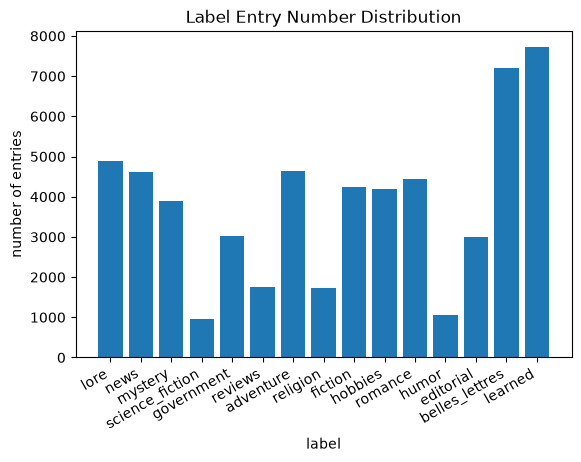

In [8]:
import matplotlib.pyplot as plt
plt.bar(entry_by_label.keys(), entry_by_label.values())
plt.title("Label Entry Number Distribution")
plt.xlabel("label")
plt.ylabel("number of entries")
plt.gca().get_figure().autofmt_xdate() # Automatically format x-tick labels to not clash
plt.show()

The uneven per-label entry count distribution, combined with the fact that each label contains entries
with equally important data and that there is no correlation between entries in different labels,
supports using a stratified approach to the split.

When splitting the dataset into a train, validation and test components, the dataset audit backs
the use of a stratified split, i.e. rather than the train percentage taken at random from the entire dataset,
the corresponding percentages will be selected from entries under each label and merged.

This ensures even data distribution in all parts of the dataset.

### Variables

The target variable is the part-of-speech tag for each specific word in a given sequence of text.
The dataset provides 3 columns, one with the raw text consisting of sentences with each word's POS tag attached,
then another one with just the words without the tags, and a third one with just the corresponding tags.

As per the Brown Corpus Manual (Francis and Kucera, 1979), there are 82 unique part-of-speech tags in the dataset.
First, we should quantify whether this matches our downloaded data or whether any outliers are present.
It's useful to both look at all the present POS tags as well as the numbers of each type,
which also provides a base target variable distribution.

In [9]:
pos_tags = set(tag for entry in df["tokenized_pos"] for tag in entry.split())
print("Unique POS tags:", len(pos_tags))

pos_tag_counts = {x: 0 for x in pos_tags}
for entry in df["tokenized_pos"]:
    for tag in entry.split():
        pos_tag_counts[tag] += 1

# Some potential outlier tags - only one occurence in entire dataset
print([x for x in pos_tag_counts if pos_tag_counts[x] == 1])

Unique POS tags: 523
['jj$-tl', 'np+hvz-nc', 'ber*-nc', 'wdt+bez-hl', 'md+ppss', 'rbr+cs', 'fw-vbg-tl', 'rb+bez-nc', 'fw-uh-tl', 'vb+jj-nc', 'nrs-tl', 'cwt', 'pps+bez-hl', 'ppss+hv-tl', '20th', 'be-tl', 'coating', '4-inch', 'rbr-nc', 'doz*-tl', 'r', '8-inch-thick', 'rb+bez-hl', 'wrb+doz', 'pn+hvd', 'ppss+ber-tl', 'hvd-hl', 'fw-jjr', 'jjr+cs', 'nn+in', 'wdt+do+pps', 'fw-dts', 'fw-ql', 'nn+hvz-tl', 'fw-rb+cc', 'wdt+ber+pp', 'vb+vb-nc', '9', 'uh-hl', 'dod*-tl', 'fw-nps-tl', 'cell', 'ppl-hl', 'nr+md', 'jj-tl-nc', 'jjt-nc', 'wdt+dod', 'in+ppo', '3%', 'nps$-hl', 'dt+bez-nc', "32''", 'destination', 'do+ppss', 'nn+hvd-tl', 'fw-uh-nc', '*-nc', 'fw-pps', 'jjs-hl', 'wrb+do', 'md*-hl', 'ppss+bez*', 'fw-od-nc', 'in+in', 'fw-vbd-tl', 'output', '7', 'g', 'wdt+ber', 'fw-to+vb', 'ppl-tl', 'active', 'wps+bez-tl', 'fw-wpo', 'dod-nc', 'sq.', 'lBOD', 'fw-nr', 'watt', '50th', 'hvg-hl', 'hr.', 'od-nc', 'ex-hl', '1', 'fw-hv', 'fw-be', 'wrb+md', 'ap+ap-nc', 'fw-nn-tl-nc', 'fw-jjt', 'ppss+ber-n', 'hp', '29', 'w

This result shows that the Kaggle-provided dataset doesn't precisely match the corpus as described in the manual.

By looking at some of the rarest of the 523 total tags that exist in the Kaggle-processed tokenised POS entries,
we can see 2 patterns emerge that will impact our data pre-processing strategy.

#### Incorrect Tokenisation

The first issue can be observed through tags such as `2-foot`, `4-inch` or `20th`.
These tags seem to look more like the actual text than the POS tags we'd expect,
which points to potentially a tokenisation/pre-processing issue within the tokenized rows obtained from Kaggle.

To verify this, we can look at the entries in which these tags appear:

In [10]:
row_2_foot = df[df["tokenized_pos"].str.contains("2-foot")]
print("Raw text containing '2-foot' tag:\n", row_2_foot["raw_text"].item())
row_4_inch = df[df["tokenized_pos"].str.contains("4-inch")]
print("Raw text containing '4-inch' tag:\n", row_4_inch["raw_text"].item())
row_20th = df[df["tokenized_pos"].str.contains("20th")]
print("Raw text containing '20th' tag:\n", row_20th["raw_text"].item())

Raw text containing '2-foot' tag:
 Hotei/np is/bez 23/cd feet/nns long/jj with/in an/at 8-1/2-foot/jj beam/nn and/cc every/at inch/nn a/at family/nn boat/nn ./.
Raw text containing '4-inch' tag:
 Lacking/vbg reliable/jj data/nn for/in some/dti of/in the/at variables/nns ,/, we/ppss are/ber relying/vbg on/in experimental/jj data/nn of/in about/rb 20/cd percent/nn internal/jj losses/nns for/in 1/4-inch/nn long/jj ,/, small/jj (/( 5/cd -/in 10/cd M/np )/) diameter/nn fibers/nns ./.
Raw text containing '20th' tag:
 Or/cc put/vbn another/dt way/nn ,/, the/at hardest/jjt missile/nn site/nn planned/vbn today/nr could/md be/be destroyed/vbn by/in placing/vbg a/at one-kiloton/nn warhead/nn (/( 1/20th/od the/at size/nn of/in those/dts used/vbn in/in Hiroshima/np and/cc Nagasaki/np )/) within/in 100/cd to/in 200/cd feet/nns of/in the/at target/nn !/. !/.


We can see that the raw data `8-1/2-foot/jj`, meaning the token `8-1/2-foot` with the POS tag `jj`,
got incorrectly split into the token `8-1` and a corresponding tag `2-foot`.
The other 2 chosen examples show analogous failures in the Kaggle-provided tokenised content.

This indicates that when working with the dataset and when preprocessing relevant data,
the `raw_text` column should be the primary source of information, and tokenisation should be done from the raw text entries,
rather than relying on the pre-tokenised columns that Kaggle provides.

#### Dataset Tag Modifiers

Unlike the previous pattern, the second observation is an intended part of the dataset.
As per the aforementioned Brown Corpus Manual (Francis and Kucera, 1979), there is a variety of modifying prefixes
and suffixes that can be attached to each valid POS tag.

These consist of the prefix `FW-` indicating a word of foreign origin and the suffixes `-TL`, `-HL` and `-NC` indicating
a word in a title, a word in a headline and a cited word, respectively.

Along with the prefixes and suffixes, some tags contain 2 types joined together with a `+` sign.
The Brown Corpus Manual notes that tags joined together with a plus sign indicate a merged construction,
for example `he'd` can be tagged `PPS+HVD` or `PPS+MD`, as `he` is a 3rd person singular nominative pronoun (`PPS` tag),
and the `'d` can be either `had` (`HVD` tag) or `would` (a modal auxiliary, `MD` tag).

Lastly, the `*` symbol, indicating a negation of a word (such as `isn't`) is attached to the end of any tag directly.

Since the Kaggle dataset tokenises the modified tags as separate strings, the various emergent combinations
will artificially inflate the total number of tags in the dataset.

### Augmented Target Variable & Preliminary Pre-processing

As per the data shown above, the version of the corpus tokenised by Kaggle is insufficient,
and, as such, it will be simplest to tokenise the `raw_text` column ourselves and disregard the tokenised columns.

For the purposes of this project, it will be sufficient to tokenise by word (i.e. split the raw text by spaces),
although more complex tokenisation approaches could be chosen for similar projects.
For example, some modern LLMs tend to tokenise based on smaller parts of text rather than entire words.
To ensure correct tag separation, each token of the raw text will be split by the last occurrence of a `/` character.

Next, while the prefixes and suffixes detailing word origin and presence are useful in the dataset,
keeping them attached would inflate the target variable class count, which could potentially worsen
model performance on some POS tags that are overall less frequent.

Adding a secondary set of target/output variables to identify the prefixes and suffixes would be possible,
but is out of this project's scope.

As such, the simplest and safest decision for this project is to exclude the prefixes and suffixes altogether.

Together, this forms the basis and justification of the pre-processing pipeline.
For the purposes of this dataset audit as an overview of what data we have available,
we can apply a simplified transformation to approximate actual target variable distribution.

Based on the conclusion of this audit, the real preprocessing pipeline will be built.

The following cell shows the transformation steps for this audit:

In [67]:
own_tokenized_words = []
own_tokenized_tags = []
own_pos_tags = {}

for entry in df["raw_text"]:
    sentence = ""
    tags = ""
    for token in entry.split():
        pair = token.rsplit("/", 1)
        sentence += pair[0].strip() + " "
        tag = pair[1].strip()
        tag = tag.replace("fw-", "").replace("-tl", "").replace("-hl", "").replace("-nc", "").replace("-n", "")
        tags += tag + " "
        if tag not in own_pos_tags:
            own_pos_tags[tag] = 1
        else:
            own_pos_tags[tag] += 1
    own_tokenized_words += sentence
    own_tokenized_tags += tags

print("Unique POS tag count:", len(own_pos_tags))
print("Unique POS tag names:", set(own_pos_tags))
print("Most frequent tag:", max(own_pos_tags, key=own_pos_tags.get), "with", own_pos_tags[max(own_pos_tags, key=own_pos_tags.get)], "occurrences")
print("Least frequent tag:", min(own_pos_tags, key=own_pos_tags.get), "with", own_pos_tags[min(own_pos_tags, key=own_pos_tags.get)], "occurrence")
print("Number of tags only appearing once:", len([x for x in own_pos_tags if own_pos_tags[x] == 1]))

Unique POS tag count: 189
Unique POS tag names: {'wpo', 'to', 'bedz', 'ber*', ':', 'pn+hvd', 'ex+hvz', 'bez', 'vbn+to', 'bem', 'in+at-t', 'dts+bez', 'qlp', 'wrb+dod', 'rb+cc', 'dtx', 'jjr', 'nn+hvd', 'hv*', ',', 'jjr+cs', 'wrb+do', 'ppss+bez*', 'nns', 'ppls', 'be', 'pp$', 'nn+in', 'md+ppss', 'jj+jj', 'nr$', 'jjt', 'nn+hvz', 'pps+md', 'ppss+hvd', 'in+in', 'wdt+do+pps', 'np+hvz', 'vb+jj', 'ex', 'ex+md', 'rbr+cs', 'jj$', 'hvd*', 'do', 'cc', 'nrs', ')', 'doz', 'ppss+md', 'cd$', 'ex+hvd', 'vb+in', 'wps', 'np+md', 'wdt+ber', 'beg', 'wrb+md', 'pps', 'ppl', 'pps+bez', 'bez*', 'hvz*', 'cd', 'ppo+in', "'", 'ap', 'wdt+bez', 'vb+at', 'in', 'ex+bez', 'ppo', 'do*', 'ppss+ber', 'pn+md', 'wrb', 'wdt+ber+pp', 'vbz', 'rbr', 'md+to', 'rb$', '(', 'at+np', 'wps+md', 'abn', 'dt+bez', 'ppss+bem', 'in+np', 'wps+hvd', 'np', 'dts', 'dt', 'np$', 'vb+to', 'dod*', 'dt+md', 'vbg+to', 'bem*', 'dti', "''", 'rb+bez', 'ap$', '.', '--', 'wp$', 'np+bez', 'ben', 'wrb+ber', 'wdt', 'vbd', 'nr+md', 'abx', 'nn$', '*', 'pn', '

Based on the transformed data, we can look at our target variable distribution.

The most basic way we can do this is to simply plot each POS tag name and then the amount of said tag in the dataset:

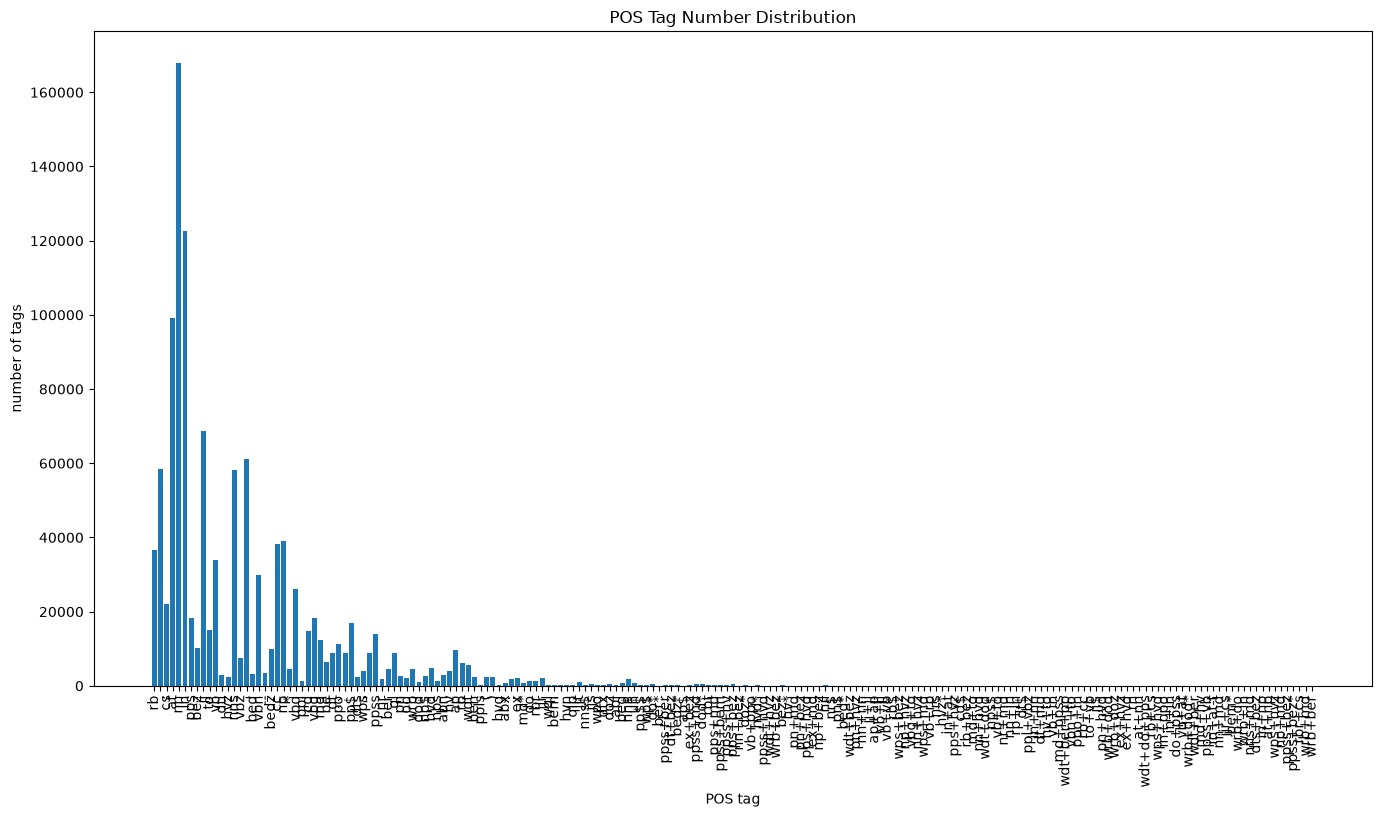

In [69]:
plt.bar([x.replace("$", "\\$") for x in own_pos_tags.keys()], own_pos_tags.values())
plt.title("POS Tag Number Distribution")
plt.xlabel("POS tag")
plt.ylabel("number of tags")
plt.xticks(rotation=90)
plt.gcf().set_size_inches(16.5, 8.5)
plt.gca().tick_params(axis="x", which="major", labelsize=10)
plt.show()

This is still a large amount of tags, which makes it difficult to clearly see the graph labels.

Overall, we can see a very outlier-heavy graph distribution, with about a third of the tags
contained in notable numbers and the rest in very small numbers.
The most frequent tag, **NN** (a singular or mass noun), is present over 160,000 times, while the least frequent tag appears only once.
As per previous code, we can see that there are 28 such tags with only one occurrence.

As a sidenote, the graph distribution and the aforementioned frequencies are a good indicator of Zipf's law,
stating that the frequency of a word in a large corpus will be inversely proportional to its rank with regard to the frequency.

An outlier-heavy target variable distribution is not necessarily an issue per say, but will need some consideration
when it comes to evaluation metrics, as with regular accuracy, a model that only detects about a third of the tags reliably
would still get a good score simply due to how many tags fall into this majority third.

Considering the scope of this project, we can reduce the outlier amount somewhat, which should make model training a bit simpler.
Since many of the outlier tags happen to be a compound of multiple tags already present (joint together with a "*+*" symbol),
we can cut down the outlier count by addressing said compounds in an additional way.

One possibility would be to introduce a second and possibly third target variable, which would be the second tag in the compound.
For the scope of this project specifically, it will be a sufficient demonstration to simply split the compound tags and use
only the first tag, typically the primary or most relevant part of the compound word.

TODO Here:
- Basically, the distribution will inform both tag splitting and evaluation metrics
- Additional evaluation metrics that weigh tags equally to account for frequent tag bias
- Most likely option is to split compound tags and only use the first tag, due to project scope


### TODO
- Missing Values (check each row for a non-zero entry tokenized, as well as each word has an adequate tag)
- Duplicates (check for fully equal tokenized text, then mention whether same POS tags as well or not)
- Outliers (entries with too many or too few words, entries with only one or two unique POS tags)

After this is done, add a conclusion which will inform the actual processing pipeline.

Processing pipeline - functor-style class or set of functions in a module, for reproducibility,
which will run and export data into a format usable by the 'models' section, so far with just the baseline model.